# GRU consumption huis




In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import time
# Gebruik de GPU als die er is, anders de CPU
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


# Data inladen

In [2]:
from pathlib import Path

#Projectmap zoeken, werkt vanuit elke submap
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
df= pd.read_parquet(ROOT / "prepared_data" / "forecast_targets_long.parquet")
huis_consumption = df[(df['location'] == 'huis') & (df['target_type'] == 'consumption')]
huis_consumption = huis_consumption.dropna(subset=['pow_imputed'])

In [3]:
huis_consumption = huis_consumption.dropna(subset=['pow_imputed'])
huis_consumption['pow_imputed'].isna().value_counts()


pow_imputed
False    231121
Name: count, dtype: int64

## voorspel instellingen

In [4]:
stap_per_dag = 24 * 12               # 288 per dag

aantal_dagen_input = 7               # aantal dagen voor input
input_len = aantal_dagen_input * stap_per_dag

aantal_dagen_forecast = 3            # =aantal dagen voorspelling
horizon = aantal_dagen_forecast * stap_per_dag

stride = 12                          # het venster schuift 12 stappen (1 uur) per voorbeeld op
TIME_COL = 'timestamp'   # pas aan naar de naam van jouw tijdkolom (of gebruik de index, zie onder)
tijd = pd.to_datetime(huis_consumption[TIME_COL])
uur = tijd.dt.hour                                   # 0 t/m 23
dag_van_week = tijd.dt.dayofweek + uur / 24          # 0.0 t/m 6.96

minuut = tijd.dt.hour * 60 + tijd.dt.minute
dag_van_week = tijd.dt.dayofweek + minuut / 1440
huis_consumption['uur_sin']  = np.sin(2 * np.pi * minuut / 1440)
huis_consumption['uur_cos']  = np.cos(2 * np.pi * minuut / 1440)
huis_consumption['week_sin'] = np.sin(2 * np.pi * dag_van_week / 7)
huis_consumption['week_cos'] = np.cos(2 * np.pi * dag_van_week / 7)
TARGET_COL = 'pow_imputed'
FEATURE_COLS = ['pow_imputed', 'uur_sin', 'uur_cos', 'week_sin', 'week_cos']   # target blijft op index 0                  # features (inclusief target)
TRAIN_FRAC = 0.70                    # deel van de data voor training
VAL_FRAC = 0.15                      # deel voor validatie data  ,de rest is test data

In [5]:
n_features = len(FEATURE_COLS)
target_idx = FEATURE_COLS.index(TARGET_COL)

## chronologisch splisen

In [6]:
values = huis_consumption[FEATURE_COLS].values.copy()
n = len(values)
i_train = int(n * TRAIN_FRAC)
i_val = int(n * (TRAIN_FRAC + VAL_FRAC))

train_raw = values[:i_train]
val_raw = values[i_train:i_val]
test_raw = values[i_val:]

In [7]:
print(type(train_raw))
print(np.isnan(train_raw).sum())

<class 'numpy.ndarray'>
0


## normaliseren

In [8]:
train_mean = train_raw.mean(axis=0)
train_std = train_raw.std(axis=0)

train = (train_raw - train_mean) / train_std
val = (val_raw - train_mean) / train_std
test = (test_raw - train_mean) / train_std

In [9]:
class WindowDataset(Dataset):

    def __init__(self, data, input_len, horizon, target_idx, stride):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.input_len = input_len
        self.horizon = horizon
        self.target_idx = target_idx

        # Hoeveel vensters passen er in de data? Elk venster heeft input_len + horizon stappen nodig
        n_vensters = len(data) - input_len - horizon + 1
        self.starts = range(0, max(n_vensters, 0), stride)

    # Bereken het aantal voorbeelden
    def __len__(self):
        return len(self.starts)

    # Haal voorbeeld nummer idx op
    def __getitem__(self, idx):
        s = self.starts[idx]
        x = self.data[s : s + self.input_len]                                   # geschiedenis
        y = self.data[s + self.input_len : s + self.input_len + self.horizon,   # toekomst,
                      self.target_idx]                                          # alleen de target
        return x, y

Creeer dataset voor de training, validatie en test data.

In [10]:
train_dataset = WindowDataset(train, input_len, horizon, target_idx, stride)
val_dataset = WindowDataset(val, input_len, horizon, target_idx, stride)
test_dataset = WindowDataset(test, input_len, horizon, target_idx, stride)

print("aantal voorbeelden | train:", len(train_dataset), "| val:", len(val_dataset), "| test:", len(test_dataset))

aantal voorbeelden | train: 13243 | val: 2650 | test: 2650


Creeer DataLoader 

In [11]:
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

## model

## training loop


In [12]:
hidden_sizes = [512,128,64]         # de GRU-lagen: aantal getallen = aantal lagen
dropout = 0.18172920761482617
learning_rate = 0.00020036334494873197
output_size = horizon


head = nn.Sequential(
    nn.Linear(hidden_sizes[-1] * 2, 256),
    nn.ReLU(),
    nn.Linear(256,256),
    nn.ReLU(),
    nn.Linear(256, output_size),
)

class Customgru(nn.Module):
    def __init__(self, input_size, hidden_sizes, head, dropout):
        super().__init__()

        self.layers = nn.ModuleList()
        self.dropout = nn.Dropout(dropout)

        prev_size = input_size
        for h in hidden_sizes:
            self.layers.append(nn.GRU(input_size=prev_size, hidden_size=h,
                                      num_layers=1, batch_first=True))
            prev_size = h

        self.head = head                 # de lagen die je hierboven zelf hebt opgeschreven

    def forward(self, x):
        out = x
        for gru in self.layers:
            out, _ = gru(out)
            out = self.dropout(out)

        laatste = out[:, -1, :]
        gem_dag = out[:, -stap_per_dag:, :].mean(dim=1)          # gemiddelde van de laatste dag
        out = torch.cat([laatste, gem_dag], dim=1)            # laatste tijdstap
        return self.head(out)

model = Customgru(
    input_size=n_features,
    hidden_sizes=hidden_sizes,
    head=head,
    dropout=dropout,
).to(DEVICE)

criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

print("CUSTOM GRU |", sum(p.numel() for p in model.parameters()), "parameters")

CUSTOM GRU | 1401824 parameters


# gridsearch

In [13]:
# import optuna
# import torch
# import torch.nn as nn
# from torch.utils.data import DataLoader
# import numpy as np

# def objective(trial):

#     # Hyperparameters zoeken
#     n_layers = trial.suggest_int("n_layers", 1,5)

#     hidden_sizes = [
#         trial.suggest_categorical(
#             f"hidden_size_{i}", [ 64, 128, 256,512]
#         )
#         for i in range(n_layers)
#     ]

#     dropout = trial.suggest_float("dropout", 0.0, 0.4)
#     learning_rate = trial.suggest_float(
#         "learning_rate", 1e-4, 1e-2, log=True
#     )
#     batch_size = trial.suggest_categorical(
#         "batch_size", [16, 32, 64 ]
#     )

#     # DataLoaders
#     train_loader_trial = DataLoader(
#         train_dataset,
#         batch_size=batch_size,
#         shuffle=True
#     )

#     val_loader_trial = DataLoader(
#         val_dataset,
#         batch_size=batch_size,
#         shuffle=False
#     )

#     # Head opnieuw maken voor de gekozen hidden size
#     output_size = horizon

#     head = nn.Sequential(
#         nn.Linear(hidden_sizes[-1] * 2, 256),
#         nn.ReLU(),
#         nn.Linear(256, 256),
#         nn.ReLU(),
#         nn.Linear(256, output_size)
#     )

#     # Nieuw model bij iedere trial
#     model = Customgru(
#         input_size=n_features,
#         hidden_sizes=hidden_sizes,
#         head=head,
#         dropout=dropout
#     ).to(DEVICE)

#     criterion = nn.L1Loss()
#     optimizer = torch.optim.Adam(
#         model.parameters(),
#         lr=learning_rate
#     )

#     n_epochs = 5
#     best_val_loss = float("inf")

#     for epoch in range(n_epochs):

#         # Trainen
#         model.train()
#         running_loss = 0.0

#         for inputs, targets in train_loader_trial:
#             inputs = inputs.to(DEVICE)
#             targets = targets.to(DEVICE)

#             optimizer.zero_grad()
#             outputs = model(inputs)
#             loss = criterion(outputs, targets)
#             loss.backward()
#             optimizer.step()

#             running_loss += loss.item() * targets.shape[0]

#         train_loss = running_loss / len(train_dataset)

#         # Valideren
#         model.eval()
#         val_loss = 0.0

#         with torch.no_grad():
#             for inputs, targets in val_loader_trial:
#                 inputs = inputs.to(DEVICE)
#                 targets = targets.to(DEVICE)

#                 outputs = model(inputs)
#                 loss = criterion(outputs, targets)

#                 val_loss += loss.item() * targets.shape[0]

#         val_loss /= len(val_dataset)

#         best_val_loss = min(best_val_loss, val_loss)
#         print(
#                 f"Trial {trial.number} | "
#                 f"Epoch {epoch + 1}/{n_epochs} | "
#                 f"Train loss: {train_loss:.4f} | "
#                 f"Val loss: {val_loss:.4f} | "
#                 f"Hidden sizes: {hidden_sizes}",
#                 flush=True
#             )
#         # Optuna volgt de validatieloss
#         trial.report(val_loss, epoch)

#         if trial.should_prune():
#             raise optuna.TrialPruned()

#     return best_val_loss

# study = optuna.create_study(
#     direction="minimize",
#     pruner=optuna.pruners.MedianPruner(
#         n_startup_trials=5,
#         n_warmup_steps=5
#     )
# )

# study.optimize(objective, n_trials=10)
# print("Beste validation loss:", study.best_value)
# print("Beste hyperparameters:", study.best_params)


#### best parameters: {'n_layers': 3, 'hidden_size_0': 512, 'hidden_size_1': 128, 'hidden_size_2': 64, 'dropout': 0.18172920761482617, 'learning_rate': 0.00020036334494873197, 'batch_size': 32}

In [14]:
n_epochs = 5

train_loss_list = []
val_loss_list = []
epoch_time_list = []

std_target = train_std[target_idx]                    # standaarddeviatie van de target

if DEVICE == "cuda":
    torch.cuda.synchronize()
start_totaal = time.perf_counter()                    # start tijd

for epoch in range(n_epochs):
    start_epoch = time.perf_counter()
    # Trainen
    model.train()
    running_loss = 0.0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)

        optimizer.zero_grad()
        output = model(inputs)
        loss = criterion(output, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * targets.shape[0]

    train_loss = running_loss / len(train_dataset)
    train_loss_list.append(train_loss)

    # Validatie
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            loss = criterion(model(inputs), targets)
            val_loss += loss.item() * targets.shape[0]
    val_loss = val_loss / len(val_dataset)
    val_loss_list.append(val_loss)

    if DEVICE == "cuda":
        torch.cuda.synchronize()
    epoch_tijd = time.perf_counter() - start_epoch    # epoch train tijd berekenen
    epoch_time_list.append(epoch_tijd)

    print(f"Epoch {epoch+1}/{n_epochs}, "
          f"train loss: {train_loss:.4f} (echte MAE: {train_loss * std_target:.1f}), "   
          f"validation loss: {val_loss:.4f} (echte MAE: {val_loss * std_target:.1f}), " 
    )
totale_tijd = time.perf_counter() - start_totaal      # totale tijd berekenen
print(f"\nTotale trainingstijd: {totale_tijd:.1f}s ({totale_tijd/60:.1f} min)")
print(f"Gemiddeld per epoch: {np.mean(epoch_time_list):.1f}s")

Epoch 1/5, train loss: 0.6494 (echte MAE: 424.0), validation loss: 1.0809 (echte MAE: 705.8), 
Epoch 2/5, train loss: 0.6311 (echte MAE: 412.1), validation loss: 1.0460 (echte MAE: 683.0), 
Epoch 3/5, train loss: 0.6248 (echte MAE: 408.0), validation loss: 1.0189 (echte MAE: 665.3), 
Epoch 4/5, train loss: 0.6215 (echte MAE: 405.8), validation loss: 1.0096 (echte MAE: 659.2), 
Epoch 5/5, train loss: 0.6193 (echte MAE: 404.4), validation loss: 1.0001 (echte MAE: 653.0), 

Totale trainingstijd: 309.4s (5.2 min)
Gemiddeld per epoch: 61.9s


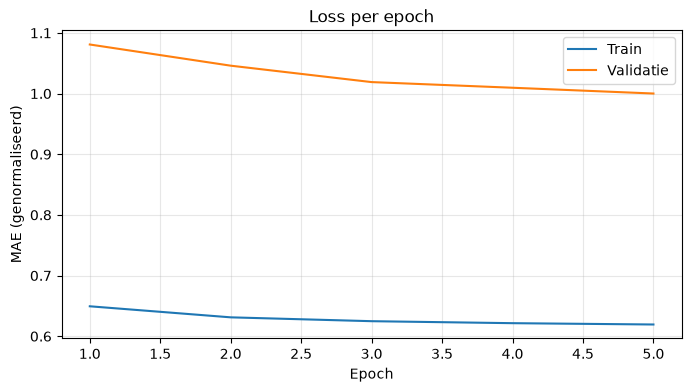

In [15]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, n_epochs + 1), train_loss_list, label='Train')
plt.plot(range(1, n_epochs + 1), val_loss_list, label='Validatie')
plt.xlabel('Epoch')
plt.ylabel('MAE (genormaliseerd)')
plt.title('Loss per epoch')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

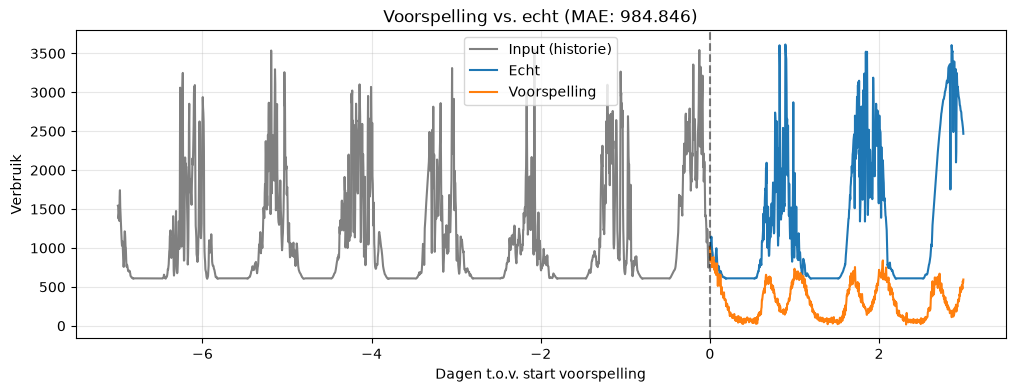

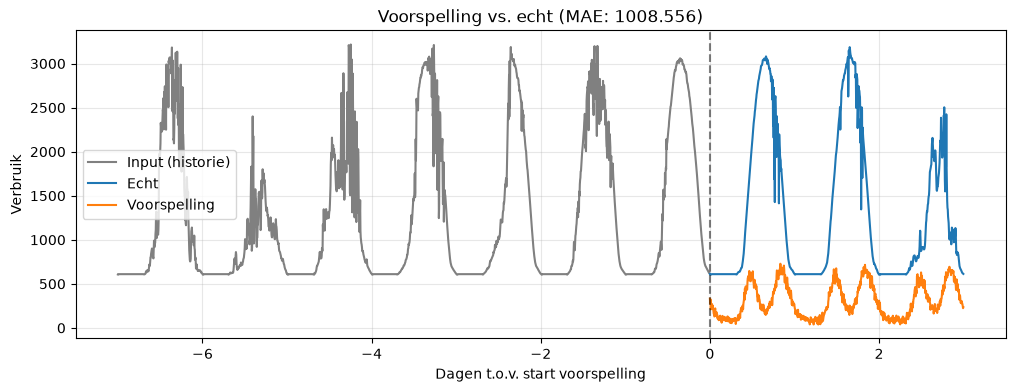

In [16]:
def plot_voorspelling(dataset, idx=0, titel='Voorspelling vs. echt'):
    model.eval()
    x, y = dataset[idx]
    with torch.no_grad():
        pred = model(x.unsqueeze(0).to(DEVICE)).cpu().numpy().flatten()

    # terug naar originele eenheid (de-normaliseren)
    m, s = train_mean[target_idx], train_std[target_idx]
    hist = x[:, target_idx].numpy() * s + m
    echt = y.numpy() * s + m
    pred = pred * s + m

    mae = np.abs(pred - echt).mean()

    t_hist = np.arange(-input_len, 0) / stap_per_dag     # x-as in dagen
    t_fc = np.arange(horizon) / stap_per_dag

    plt.figure(figsize=(12, 4))
    plt.plot(t_hist, hist, color='grey', label='Input (historie)')
    plt.plot(t_fc, echt, label='Echt')
    plt.plot(t_fc, pred, label='Voorspelling')
    plt.axvline(0, color='black', linestyle='--', alpha=0.5)
    plt.xlabel('Dagen t.o.v. start voorspelling')
    plt.ylabel('Verbruik')
    plt.title(f'{titel} (MAE: {mae:.3f})')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_voorspelling(test_dataset, idx=0)
plot_voorspelling(test_dataset, idx=len(test_dataset) // 2)   # een ander moment

## Resultaten opslaan
---
- Zelfde format als de andere modellen, opgeslagen in `models/results/`
- MAE in Watt op alle testvensters (elk uur een nieuwe forecast van 3 dagen)
- Persistence dag = zelfde tijdstip van de meest recente bekende dag, persistence week = zelfde tijdstip een week eerder

In [17]:
from pathlib import Path

MODEL_NAAM = "GRU"
NOTEBOOK = "gru_consumption_huis"
TARGET = "consumption"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
RESULTS_DIR = ROOT / "models" / "results"
MODEL_DIR = ROOT / "models" / "saved_models"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

#Voorspellen op alle testvensters, test_loader schudt niet dus de volgorde klopt
model.eval()
preds, targets_norm = [], []
if DEVICE == "cuda":
    torch.cuda.synchronize()
t0 = time.perf_counter()
with torch.no_grad():
    for inputs, targets in test_loader:
        preds.append(model(inputs.to(DEVICE)).cpu())
        targets_norm.append(targets)
if DEVICE == "cuda":
    torch.cuda.synchronize()
voorspeltijd = time.perf_counter() - t0

m, s = train_mean[target_idx], train_std[target_idx]
pred_test = torch.cat(preds).numpy() * s + m

#Echte waarden en baselines direct uit de reeks in Watt
y_arr = huis_consumption[TARGET_COL].to_numpy()
test_origins = i_val + input_len + np.array(test_dataset.starts)
h = np.arange(horizon)
t = test_origins[:, None] + h[None, :]
echt_test = y_arr[t]
base_dag = y_arr[t - stap_per_dag * (h // stap_per_dag + 1)]
base_week = y_arr[t - input_len]
assert np.allclose(torch.cat(targets_norm).numpy() * s + m, echt_test, atol=1.0), "testvensters komen niet overeen"


def scores(pred, echt):
    fout = pred - echt
    res = {"MAE": np.abs(fout).mean(), "RMSE": np.sqrt((fout ** 2).mean())}
    for d in range(aantal_dagen_forecast):
        sl = slice(d * stap_per_dag, (d + 1) * stap_per_dag)
        res[f"MAE dag {d+1}"] = np.abs(fout[:, sl]).mean()
    #Rolling validation: elke dag een nieuwe forecast
    dagelijks = slice(None, None, stap_per_dag // stride)
    res["rolling MAE"] = np.abs(fout[dagelijks]).mean(axis=1).mean()
    res["rolling RMSE"] = np.sqrt((fout[dagelijks] ** 2).mean(axis=1)).mean()
    return res

alle = {MODEL_NAAM: pred_test, "Persistence dag": base_dag, "Persistence week": base_week}
resultaten = pd.DataFrame({naam: scores(pred, echt_test) for naam, pred in alle.items()}).T
resultaten.loc[MODEL_NAAM, "trainingstijd (s)"] = totale_tijd
resultaten.loc[MODEL_NAAM, "voorspeltijd (s)"] = voorspeltijd
resultaten = resultaten.round(1)

#Model opslaan en bestandsgrootte meten
pad = MODEL_DIR / f"{NOTEBOOK}.pt"
torch.save(model.state_dict(), pad)
resultaten.loc[MODEL_NAAM, "modelgrootte (MB)"] = round(pad.stat().st_size / 1e6, 3)

KOLOMMEN = ["notebook", "locatie", "target", "resolutie", "testperiode", "MAE", "RMSE", "MAE dag 1", "MAE dag 2",
            "MAE dag 3", "rolling MAE", "rolling RMSE", "trainingstijd (s)", "voorspeltijd (s)",
            "modelgrootte (MB)"]
tijden = pd.to_datetime(huis_consumption["timestamp"])
resultaten["notebook"] = NOTEBOOK
resultaten["locatie"] = "huis"
resultaten["target"] = TARGET
resultaten["resolutie"] = "5 min"
resultaten["testperiode"] = f"{tijden.iloc[i_val]:%Y-%m-%d} t/m {tijden.iloc[-1]:%Y-%m-%d}"
resultaten = resultaten.reindex(columns=KOLOMMEN)
resultaten.to_csv(RESULTS_DIR / f"{NOTEBOOK}.csv")
resultaten

,notebook,locatie,target,resolutie,testperiode,MAE,RMSE,MAE dag 1,MAE dag 2,MAE dag 3,rolling MAE,rolling RMSE,trainingstijd (s),voorspeltijd (s),modelgrootte (MB)
GRU,gru_consumption_huis,huis,consumption,5 min,2026-05-12 t/m 2026-09-10,910.2,1170.3,898.9,912.0,919.5,908.0,1149.9,309.4,4.5,5.612
Persistence dag,gru_consumption_huis,huis,consumption,5 min,2026-05-12 t/m 2026-09-10,266.8,514.9,259.5,263.3,277.6,267.0,493.6,NaN,NaN,NaN
Persistence week,gru_consumption_huis,huis,consumption,5 min,2026-05-12 t/m 2026-09-10,324.0,591.7,324.4,324.2,323.5,324.0,579.4,NaN,NaN,NaN
